<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/03-random-forest/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.3 · Random Forest: ¿vale la pena?

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Qué es un **bosque**: muchos árboles que se promedian.
- Qué dice, y qué no dice, la **importancia de las variables**.
- Por qué **más complejo no siempre significa mejor**.

## 📊 En Excel lo harías así

Pides el mismo pronóstico a varios colegas, y calculas `=PROMEDIO()` (`AVERAGE`) de sus respuestas. Cada uno se equivoca, pero no en lo mismo, y el promedio suele ser más estable que cualquiera de ellos.

Un **bosque** (*Random Forest*) hace eso con árboles. Cada uno aprende con una muestra distinta de los datos, y al final se promedian.

## 🐍 En Python

### Paso 1: los mismos datos

Usamos los despachos del 2.1 y la medida del 2.2: la parte de tardíos encontrada vigilando el 10 % de cada día.

> ⚠️ **Datos sintéticos**, con reglas publicadas en `catalogos.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def preparar_despachos(despachos):
    """Deja los datos que se conocen al preparar un despacho: textos como 0 y 1, mes y día."""
    fecha = pd.to_datetime(despachos["fecha"])
    x = pd.get_dummies(despachos[["ciudad", "tipo", "transportista"]], dtype=int)
    x = x.drop(columns=["ciudad_Lima", "tipo_Bodega", "transportista_Propio"], errors="ignore")
    x["mes"] = fecha.dt.month
    x["dia"] = fecha.dt.dayofweek
    return x.join(despachos[["distancia_km", "lineas", "presentaciones"]])

In [3]:
def parte_encontrada(periodo, real, probabilidad, vigilar=0.10):
    """Parte de los casos reales hallada al vigilar, en cada periodo, a los de mayor riesgo."""
    orden = pd.DataFrame({"periodo": periodo, "real": real, "probabilidad": probabilidad})
    orden["azar"] = np.random.default_rng(0).random(len(orden))
    orden = orden.sort_values(["periodo", "probabilidad", "azar"], ascending=[True, False, True])
    puesto = orden.groupby("periodo").cumcount()
    cupo = (orden.groupby("periodo")["real"].transform("size") * vigilar).round().clip(lower=1)
    return orden.loc[puesto < cupo, "real"].sum() / orden["real"].sum()

In [4]:
despachos = pd.read_csv(DATOS + "despachos.csv")

entreno = despachos[despachos["fecha"] < "2025-07-01"]
prueba = despachos[despachos["fecha"] >= "2025-07-01"]

x_entreno = preparar_despachos(entreno)
x_prueba = preparar_despachos(prueba)

### Paso 2: el bosque

`RandomForestClassifier` se entrena igual. Dos valores:

- `n_estimators=200`: cuántos árboles.
- `min_samples_leaf=20`: cada hoja debe tener al menos 20 casos, para que no memorice casos sueltos. **Es un valor fijo: aquí no lo ajustamos**, a diferencia de la profundidad del 2.2.

`n_jobs=-1` solo le pide a Colab usar todos sus procesadores.

In [5]:
bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1)
bosque.fit(x_entreno, entreno["llego_tarde"])

arbol = DecisionTreeClassifier(max_depth=6, random_state=0)
arbol.fit(x_entreno, entreno["llego_tarde"])

prob_bosque = bosque.predict_proba(x_prueba)[:, 1]
prob_arbol = arbol.predict_proba(x_prueba)[:, 1]

print("Árbol:", round(parte_encontrada(prueba["fecha"], prueba["llego_tarde"], prob_arbol), 3))
print("Bosque:", round(parte_encontrada(prueba["fecha"], prueba["llego_tarde"], prob_bosque), 3))

Árbol: 0.291
Bosque: 0.294


**Empatan.** 200 árboles encuentran lo mismo que uno, y perdimos algo: el árbol se puede leer, y el bosque no. Con otros datos, puede ganar cualquiera de los dos por un par de puntos.

Un detalle de método: es la misma prueba del 2.2. La reusamos para aprender, pero en un proyecto real compararías en validación y dejarías la prueba para el final.

### Paso 3: la importancia

Como no se puede leer, el bosque ofrece un resumen: cuánto usó cada columna.

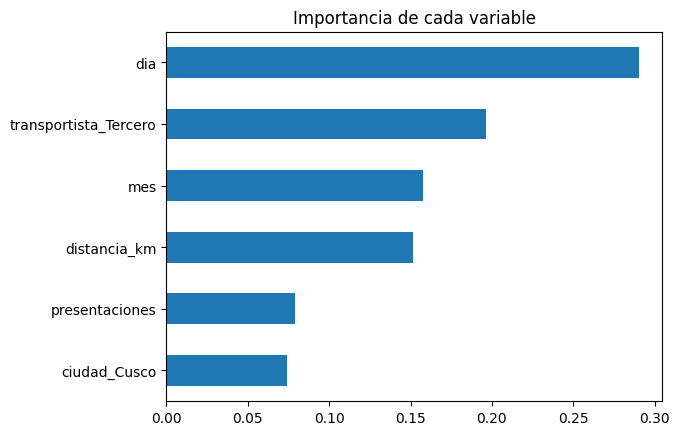

In [6]:
importancia = pd.Series(bosque.feature_importances_, index=x_entreno.columns)

importancia.sort_values().tail(6).plot(kind="barh", title="Importancia de cada variable")
plt.show()

Cuidado con lo que esto significa. `dia` sale primera, pero el sábado solo importa **junto con** un transportista tercero. Y `distancia_km` casi solo importa junto con la lluvia en Cusco. La importancia te dice **qué tanto se usó una columna, no cómo actúa**. Y no prueba que sea la causa de nada.

Además, las columnas con muchos valores distintos, como la distancia, tienen más oportunidades de ser elegidas y salen infladas. Toma el orden como una orientación.

### Paso 4: un caso donde no aporta nada

La mora de `creditos.csv` se programó sumando efectos. Con la receta del 1.7, vigilando el 10 % de las compras de cada mes:

In [7]:
def preparar_creditos(creditos):
    """Agrega las variables del modelo y separa entrenamiento y prueba al 1 de julio de 2025."""
    tabla = creditos.assign(
        log_monto=np.log(creditos["monto_sobre_limite"]),
        tasa_previa=(creditos["morosos_previos"] / creditos["casos_previos"]).fillna(0),
        sin_historial=(creditos["casos_previos"] == 0).astype(int),
    )
    fecha = pd.to_datetime(tabla["fecha"])
    se_sabe = fecha + pd.to_timedelta(tabla["plazo_dias"] + 31, unit="D")
    con_resultado = tabla["moroso"].notna()
    corte = pd.Timestamp("2025-07-01")
    return tabla[(se_sabe <= corte) & con_resultado], tabla[(fecha >= corte) & con_resultado]

In [8]:
def preparar_x(tabla, numeros, textos, columnas=None):
    """Convierte los textos en columnas de 0 y 1. Con `columnas`, usa las de entrenamiento."""
    x = pd.get_dummies(tabla[numeros + textos], columns=textos, dtype=float)
    if columnas is not None:
        x = x.reindex(columns=columnas, fill_value=0)
    return x

In [9]:
creditos = pd.read_csv(DATOS + "creditos.csv")
cred_entreno, cred_prueba = preparar_creditos(creditos)

numeros = ["log_monto", "antiguedad_anios", "tasa_previa", "sin_historial"]
textos = ["tipo"]
x_cred_entreno = preparar_x(cred_entreno, numeros, textos)
x_cred_prueba = preparar_x(cred_prueba, numeros, textos, x_cred_entreno.columns)

mes = cred_prueba["fecha"].str[:7]
print(len(cred_entreno), len(cred_prueba))

5408 1531


In [10]:
modelos = {
    "regresion": make_pipeline(StandardScaler(), LogisticRegression()),
    "arbol": DecisionTreeClassifier(max_depth=3, random_state=0),
    "bosque": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1
    ),
}
for nombre, modelo in modelos.items():
    modelo.fit(x_cred_entreno, cred_entreno["moroso"])
    prob = modelo.predict_proba(x_cred_prueba)[:, 1]
    print(nombre, round(parte_encontrada(mes, cred_prueba["moroso"], prob), 3))

regresion 0.296
arbol 0.26


bosque 0.278


Quedan a la par: son unos 66, 58 y 62 de 223 morosos, y el orden cambia con otros datos. Aquí un modelo más complejo no aporta nada.

Antes de buscar un modelo más complejo, pregúntate:

- ¿Gana por una diferencia que le importe al negocio?
- ¿Vale perder la posibilidad de explicarlo?
- ¿Lo probaste contra algo simple?

## 🤖 Pídeselo a la IA

> *"Mi jefe vio un gráfico de importancia de variables, donde 'día de la semana' es la primera, y quiere cambiar el calendario de despachos. Explícame por qué eso no basta para decidirlo."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| `=PROMEDIO()` (`AVERAGE`) de varias opiniones | `RandomForestClassifier(n_estimators=200)` |
| Ver qué columnas pesan | `bosque.feature_importances_` |
| Comparar con algo simple | La misma medida para ambos modelos |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/03-random-forest/ejercicio.ipynb) y compara modelos con otros datos. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/03-random-forest/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0